In [1]:
import numpy as np 
import pandas as pd 
from sklearn.datasets import load_breast_cancer 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import( 
accuracy_score, 
precision_score, 
recall_score, 
f1_score, 
confusion_matrix, 
classification_report 
) 
data = load_breast_cancer() 
X = pd.DataFrame( 
data.data, 
columns=data.feature_names 
) 
y = pd.Series (data.target, name="target") 
print("Dataset shape:", X.shape) 
print("\nFirst 5 rows:") 
display(X.head()) 

Dataset shape: (569, 30)

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
print("Number of samples:", X.shape[0]) 
print("Number of features:", X.shape[1]) 
print("\nTarget distribution:") 
print(y.value_counts()) 
print("\nMissing values:") 
print(X.isnull().sum().sum()) 

Number of samples: 569
Number of features: 30

Target distribution:
target
1    357
0    212
Name: count, dtype: int64

Missing values:
0


In [3]:
X_train, X_test, y_train, y_test = train_test_split( 
X, 
y, 
test_size=0.2, 
random_state=42, 
stratify=y 
)

print("\nTraining samples:", X_train.shape[0]) 
print("Testing samples:", X_test.shape[0]) 


Training samples: 455
Testing samples: 114


In [4]:
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.transform(X_test) 
print("Training data shape:", X_train_scaled.shape) 
print("Testing data shape:", X_test_scaled.shape) 

Training data shape: (455, 30)
Testing data shape: (114, 30)


In [5]:
baseline_model = LogisticRegression( 
max_iter=2000 
) 
baseline_model.fit( 
X_train_scaled, 
y_train 
) 
baseline_pred = baseline_model.predict( 
X_test_scaled 
) 
baseline_accuracy = accuracy_score( 
y_test, 
baseline_pred 
) 
print("\nBaseline Accuracy:", baseline_accuracy) 


Baseline Accuracy: 0.9824561403508771


In [6]:
def fitness_function(position): 
    selected = position > 0.5 
    if not np.any(selected): 
        return 0 
    X_selected = X_train_scaled[:, selected] 
    model = LogisticRegression( 
        max_iter=2000 
    ) 
    model.fit( 
        X_selected,
         y_train 
        ) 
    predictions = model.predict( 
        X_selected 
    ) 
    accuracy = accuracy_score( 
        y_train, 
        predictions 
    ) 
    return accuracy 


In [7]:
from sklearn.model_selection import cross_val_score 
def fitness_function(position): 
    selected = position > 0.5 
    if not np.any(selected): 
        return 0 
    X_selected = X_train_scaled[:, selected] 
    model = LogisticRegression( 
        max_iter=2000) 
    scores = cross_val_score(model, 
    X_selected, 
    y_train, 
    cv=5, 
    scoring="accuracy") 
    return scores.mean() 


In [8]:
n_particles = 15 
n_features = X_train_scaled.shape[1] 

n_iterations = 30 

w = 0.7 
c1 = 1.5 
c2 = 1.5 

np.random.seed(42) 

positions = np.random.rand( 
    n_particles, 
    n_features 
) 

velocities = np.random.uniform( 
    -1, 
    1, 
size=(n_particles, n_features) 
) 


In [18]:
pbest_positions = positions.copy()

pbest_scores = np.array([
    fitness_function(position)
    for position in positions])
best_index = np.argmax(pbest_scores)

gbest_position = pbest_positions[
    best_index
].copy()

gbest_score = pbest_scores[
    best_index
]

print("Initial Best Fitness:", gbest_score)
                       

Initial Best Fitness: 0.9780219780219781


In [19]:
history = []

for iteration in range(n_iterations):

    for i in range(n_particles):

        #random values
        r1 = np.random.rand(n_features)
        r2 = np.random.rand(n_features)

        #Update velocity
        velocities[i] = (
        w * velocities[i]
        + c1 * r1 * 
            (pbest_positions[i] - positions[i])
        + c2 * r2 *
            (gbest_position - positions[i]) 
        )

        # Update position
        positions[i] = (
            positions[i] + velocities[i]
        )
        
        #keep position between 0 and 1 
        positions[i] = np.clip(
            positions[i],
            0,
            1 )

In [23]:
#Calculate fitness
score = fitness_function(
    positions[i]
)

#Update personal best
if score > pbest_scores[i]:

    pbest_scores[i] = score

    pbest_positions[i] = (
        positions[i].copy())

#Update global best
if score > gbest_score:
    gbest_score = score

    gbest_position = (
        positions[i].copy()
    )

history.append(gbest_score)

    print( f"Iteration {iteration + 1:02d} "
          f"| Best Fitness = {gbest_score:.4f}")


IndentationError: unexpected indent (1629216521.py, line 24)

In [25]:
best_features_mask = gbest_position > 0.5 

selected_feature_names = X.columns[ 
    best_features_mask 
] 

print("\nSelected Features:") 
for feature in selected_feature_names: 
    print(feature) 
    
print( "\nNumber of selected features:", 
len(selected_feature_names) 
) 

print( "Best CV Accuracy:", 
gbest_score)


Selected Features:
mean texture
mean perimeter
mean area
mean smoothness
mean concavity
texture error
area error
smoothness error
concave points error
worst perimeter
worst area
worst smoothness
worst compactness
worst concavity
worst symmetry
worst fractal dimension

Number of selected features: 16
Best CV Accuracy: 0.9780219780219781


## Train Final Logistic Regression

In [26]:
X_train_pso = X_train_scaled[
    :, best_features_mask
]
X_test_pso = X_test_scaled[
    :, best_features_mask
]

final_model = LogisticRegression(
    max_iter= 2000)
final_model.fit(
    X_train_pso,
    y_train
)

final_pred = final_model.predict(X_test_pso)

## Evaluate the Final Model

In [29]:
accuracy = accuracy_score(y_test, final_pred)
precision = precision_score(y_test, final_pred)
recall = recall_score(y_test, final_pred)
f1 = f1_score(y_test, final_pred)

print("PSO + Logistic Regression")
print("-------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall  :", recall)
print("F1 Score :", f1)

PSO + Logistic Regression
-------------------------
Accuracy : 0.9649122807017544
Precision: 0.9857142857142858
Recall  : 0.9583333333333334
F1 Score : 0.971830985915493


In [30]:
cm = confusion_matrix(
    y_test, final_pred)

print("Confusion Matrix: ")
print(cm)

Confusion Matrix: 
[[41  1]
 [ 3 69]]


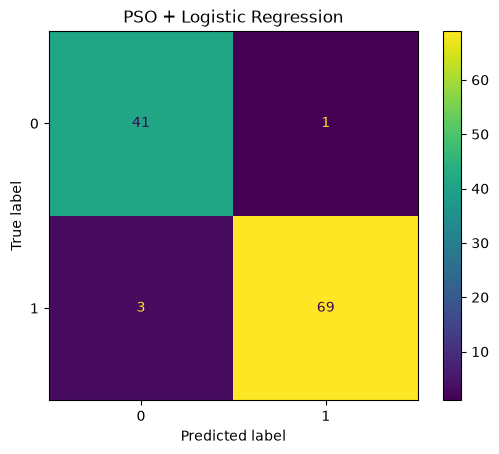

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm).plot()

plt.title("PSO + Logistic Regression")
plt.show()

# Comapare Before and After PSO

## This is an important part of practical

In [34]:
print("Performance Comparison")
print("----------------------")

print("All Features:")
print("Number of Features:", X.shape[1])
print("Accuracy:", baseline_accuracy)

print("\nPSO Selectede Features:")
print("Number of Features:", 
     len(selected_feature_names))

print("Accuracy:", accuracy)

Performance Comparison
----------------------
All Features:
Number of Features: 30
Accuracy: 0.9824561403508771

PSO Selectede Features:
Number of Features: 16
Accuracy: 0.9649122807017544


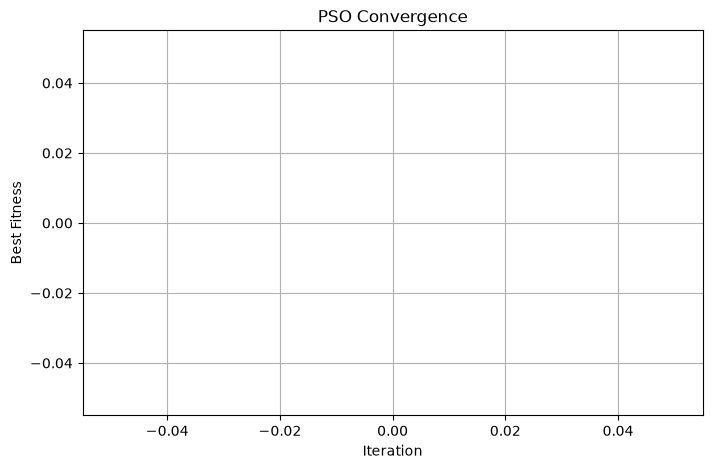

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, len(history) + 1),
         history,
         marker='o')

plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence")
plt.grid(True)

plt.show()
